In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D,Activation, MaxPooling2D, UpSampling2D, Concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda, ReLU
from tensorflow.keras.applications import ResNet101
import numpy as np
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping,ReduceLROnPlateau, CSVLogger
from tensorflow.keras.applications.resnet import preprocess_input
from tensorflow.keras.metrics import MeanIoU
import keras
from keras import ops


In [3]:
# hiper parametros
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.00001

In [ ]:
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

In [ ]:
#mesmo bloco de convolução da arquitetura U-Net
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [ ]:
def decoder_resnet(inputs,skips, filters):
    x = Conv2DTranspose(filters, (2,2), strides=2, padding="same")(inputs)
    x = Concatenate()([x,skips])

    x = convolucao(x,filters)
    return x

In [ ]:
def resnet101_unet(input_shape):
    inputs = Input(input_shape)

    input = preprocess_input(inputs)

    resnet = ResNet101(include_top=False, weights="imagenet", input_tensor=input)

    s1 = inputs
    s2 = resnet.get_layer("conv1_relu").output
    
    s3 = resnet.get_layer("conv2_block3_out").output
    s4 = resnet.get_layer("conv3_block4_out").output

    b1 = resnet.get_layer("conv4_block23_out").output

    d1 = decoder_resnet(b1, s4, 512)
    d2 = decoder_resnet(d1, s3, 256)
    d3 = decoder_resnet(d2, s2, 128)
    d4 = decoder_resnet(d3, s1, 64)

    outputs = Conv2D(5,1, padding='same',activation='softmax')(d4)

    model = Model(inputs,outputs)
    return model

In [ ]:
model = resnet101_unet((height_img, width_img, canais))


171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 288, 288)  │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 288, 288,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 288, 288,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 294, 294,  │          0 │ add[0][0]         │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 144, 144,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 144, 144,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 144, 144,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 146, 146,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 72, 72,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 72, 72,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 72, 72,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 72, 72,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 72, 72,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 72, 72,    │        256 │ conv2_block1_2_c

 Total params: 39,747,269 (151.62 MB)

 Trainable params: 39,660,613 (151.29 MB)

 Non-trainable params: 86,656 (338.50 KB)

In [ ]:
dice = keras.losses.Dice(axis=(0, 1, 2))
# loss dice oficial do keras, com axis=(0, 1, 2) calcula o dice separado para cada uma das 5 classes e depois faz a media
# assim o fundo pesa como uma parte em 5 na imagem e nao domina como acontece na acuracia
# o dice precisa da mascara em one-hot, no mesmo formato da saida do softmax
ce = keras.losses.SparseCategoricalCrossentropy()

def ce_dice_loss(y_true, y_pred):
    y_true_oh = ops.one_hot(ops.cast(ops.squeeze(y_true, axis=-1), 'int32'), 5)
    # transforma a mascara de inteiros (0 a 4) em one-hot
    return ce(y_true, y_pred) + dice(y_true_oh, y_pred)

In [ ]:
model.compile(optimizer=Adam(learning_rate=lr), loss=ce_dice_loss, metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False)])

In [12]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_dice.keras'


In [ ]:
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')
early_stopper = EarlyStopping(patience = 8, monitor='val_loss')
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.000001, verbose=1)

checks = [checkpointer, lr_reducer, early_stopper]


In [ ]:
# treino do modelo
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 691ms/step - loss: 2.1371 - mean_io_u: 0.1258
Epoch 1: val_mean_io_u improved from None to 0.25647, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_dice.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_dice.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 387s 835ms/step - loss: 1.9828 - mean_io_u: 0.1688 - val_loss: 1.7549 - val_mean_io_u: 0.2565 - learning_rate: 1.0000e-05
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - loss: 1.5855 - mean_io_u: 0.3087
Epoch 2: val_mean_io_u improved from 0.25647 to 0.47440, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_dice.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_

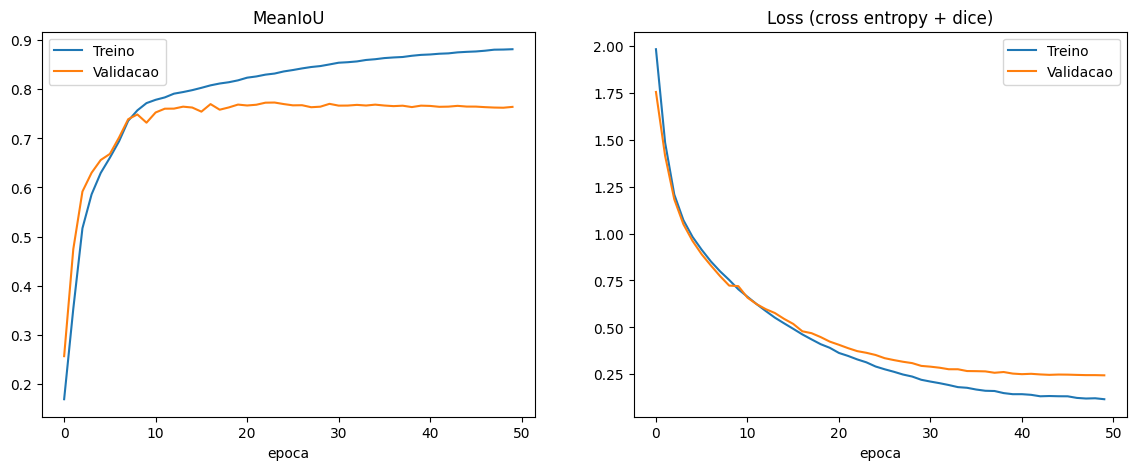

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss (cross entropy + dice)')
plt.xlabel('epoca')
plt.legend()

plt.show()
